

# Customer Reviews Analysis: NLP, Time Series, and Neural Networks

## Project Overview

This project analyzes Amazon customer reviews using three data science approaches:

1. **Natural Language Processing (NLP):** Clean and preprocess review text, identify frequent words and phrases, and explore customer feedback patterns.
2. **Time Series Analysis:** Examine monthly review volume and average ratings over time to identify trends and changes in customer feedback.
3. **Neural Networks:** Use TF-IDF text features and a neural network to predict customer ratings from review text.

## Objectives

- Extract useful insights from customer review text.
- Explore changes in review activity and ratings over time.
- Build and evaluate a neural network for multi-class rating prediction.
- Identify limitations and recommend improvements based on the results.

## Dataset

The analysis uses `amazon_reviews_lab.csv`, which contains customer review text, ratings, timestamps, and related review information.

## Tools and Libraries

Python, Pandas, NumPy, Matplotlib, Seaborn, NLTK, Scikit-learn, Statsmodels, and TensorFlow/Keras.

## Project Workflow

Data loading and preparation → Text preprocessing and exploration → Time series analysis → Neural network modelling → Evaluation and recommendations.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter


# For text preprocessing
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.util import ngrams


# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')


# For dataset loading
from sklearn.datasets import fetch_20newsgroups


# Set random seed for reproducibility
np.random.seed(42)


# Load a subset of the 20 Newsgroups dataset
categories = ['comp.graphics', 'rec.autos', 'sci.space', 'talk.politics.misc']
newsgroups = fetch_20newsgroups(subset='train', categories=categories, random_state=42)


# Create a DataFrame for easier manipulation
df = pd.DataFrame({
   'text': newsgroups.data,
   'category': [newsgroups.target_names[target] for target in newsgroups.target]
})


# Preview the data
print(f"Dataset shape: {df.shape}")
print("\nCategory distribution:")
print(df['category'].value_counts())
print("\nSample document:")
print(df['text'][10][:500])  # Print first 500 characters of a sample document

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_en

Dataset shape: (2236, 2)

Category distribution:
category
rec.autos             594
sci.space             593
comp.graphics         584
talk.politics.misc    465
Name: count, dtype: int64

Sample document:
From: bob1@cos.com (Bob Blackshaw)
Subject: Re: Dumbest Driver Action
Organization: Corporation for Open Systems
Distribution: usa 
Lines: 41

In <C5Dq2n.5uB@news.cso.uiuc.edu> mwbg9715@uxa.cso.uiuc.edu (Mark Wayne Blunier) writes:

>jimf@centerline.com (Jim Frost) writes:

>>I wish I had the figures with me to back me up, but I recall
>>statistics showing that women tended to have more accidents than men
>>but the damage was generally quite minor.  Men had fewer but far more
>>expensive acciden


In [2]:
# Load the Amazon reviews dataset
df = pd.read_csv("amazon_reviews_lab.csv")

# Check dataset shape
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check rating distribution
print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

# Preview the first five rows
display(df.head())

Dataset shape: (997, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 70.2+ KB

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [ ]:
#Create preprocessing tools

from html import unescape

stop_words = set(stopwords.words("english"))

# Keep words that are important for sentiment
stop_words = stop_words - {"no", "nor", "not"}

lemmatizer = WordNetLemmatizer()

In [4]:
def preprocess_text(text):
    if pd.isna(text):
        return []

    # Convert to lowercase and decode HTML entities
    text = unescape(str(text).lower())

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Tokenize the text
    tokens = word_tokenize(text)

    # Keep alphabetic tokens, remove stopwords, and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    return cleaned_tokens

### Preprocessing Recommendation and Risk

The reviews are converted to lowercase, cleaned of URLs and punctuation, tokenized, filtered to remove common stopwords, and lemmatized to standardize word forms.

**Risk:** Removing stopwords can change the meaning of a review, particularly when words such as "not" indicate negative sentiment. We therefore retain "no," "nor," and "not" during preprocessing. HTML entities are also decoded to reduce noise in the text.

In [6]:
df["processed_tokens"] = df["review_text"].apply(preprocess_text)

# Preview original text and cleaned tokens
display(df[["review_text", "processed_tokens"]].head())

,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, not, anyone, especially, fo..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."


In [7]:
# Combine tokens from all reviews
all_tokens = [
    token
    for review_tokens in df["processed_tokens"]
    for token in review_tokens
]

# Count word frequencies
word_counts = Counter(all_tokens)

# Display the 20 most common words
common_words = word_counts.most_common(20)

print("Most common words:")
print(common_words)

Most common words:
[('nook', 1510), ('not', 1044), ('book', 913), ('one', 569), ('kindle', 561), ('screen', 496), ('like', 459), ('read', 454), ('work', 446), ('get', 424), ('great', 422), ('use', 420), ('tablet', 419), ('tv', 416), ('no', 387), ('device', 381), ('would', 378), ('good', 331), ('bn', 321), ('time', 318)]


## NLP Findings: Most Common Words

The most frequent word was **"nook" (1,510 occurrences)**, followed by "not" (1,044), "book" (913), "one" (569), and "kindle" (561). Other frequently occurring words included "screen," "read," "work," "great," "use," and "tablet."

These results suggest that the reviews focus heavily on the **Nook device, reading experiences, device functionality, and comparisons with Kindle**. The frequent appearance of "screen" may indicate that display quality or screen functionality is an important topic for customers.

The word "not" appeared 1,044 times, making it the second most frequent word. This suggests that negative statements or expressions of limitations may be important in the reviews. However, the presence of "not" alone does not establish that the overall customer sentiment is negative. Similarly, words such as "great" and "good" indicate positive expressions but do not establish the overall sentiment.

### Business Implication

The business could investigate reviews mentioning the screen, device functionality, reading experience, and comparisons with competing products. These topics may reveal opportunities to improve the product and strengthen its competitive position.

In [11]:
all_bigrams = [
    bigram
    for tokens in df["processed_tokens"]
    for bigram in ngrams(tokens, 2)
]

bigram_counts = Counter(all_bigrams)
common_bigrams = bigram_counts.most_common(20)

print("Most common bigrams:")
print(common_bigrams)

Most common bigrams:
[(('barnes', 'noble'), 152), (('nook', 'color'), 127), (('battery', 'life'), 87), (('touch', 'screen'), 81), (('sd', 'card'), 80), (('nook', 'hd'), 74), (('work', 'great'), 63), (('nook', 'tablet'), 63), (('work', 'well'), 57), (('read', 'book'), 55), (('kindle', 'fire'), 55), (('wall', 'mount'), 51), (('no', 'problem'), 50), (('simple', 'touch'), 44), (('android', 'tablet'), 39), (('customer', 'service'), 38), (('nook', 'simple'), 37), (('bn', 'store'), 35), (('easy', 'install'), 34), (('original', 'nook'), 34)]


## NLP Findings: Most Common Bigrams

The most frequent bigram was **"barnes noble" (152 occurrences)**, followed by "nook color" (127), "battery life" (87), "touch screen" (81), and "sd card" (80). Other frequent phrases included "nook hd," "work great," "work well," "read book," and "customer service."

These phrases provide more context than individual word frequencies:

- **Product and brand references:** "barnes noble," "nook color," "nook hd," and "nook tablet" show that reviews frequently discuss specific Nook products and their brand.
- **Device performance and features:** "battery life," "touch screen," and "sd card" suggest that battery performance, screen interaction, and storage are relevant topics for customers.
- **Positive experiences:** "work great" and "work well" indicate that some customers describe products or features as functioning satisfactorily.
- **Customer support:** "customer service" indicates that support experiences also appear in the reviews.

### Business Implication

The business should examine reviews about battery life, touch-screen performance, storage, and customer service to identify recurring concerns and opportunities for improvement. Positive phrases such as "work great" can also help identify features that customers appreciate and that should be maintained.

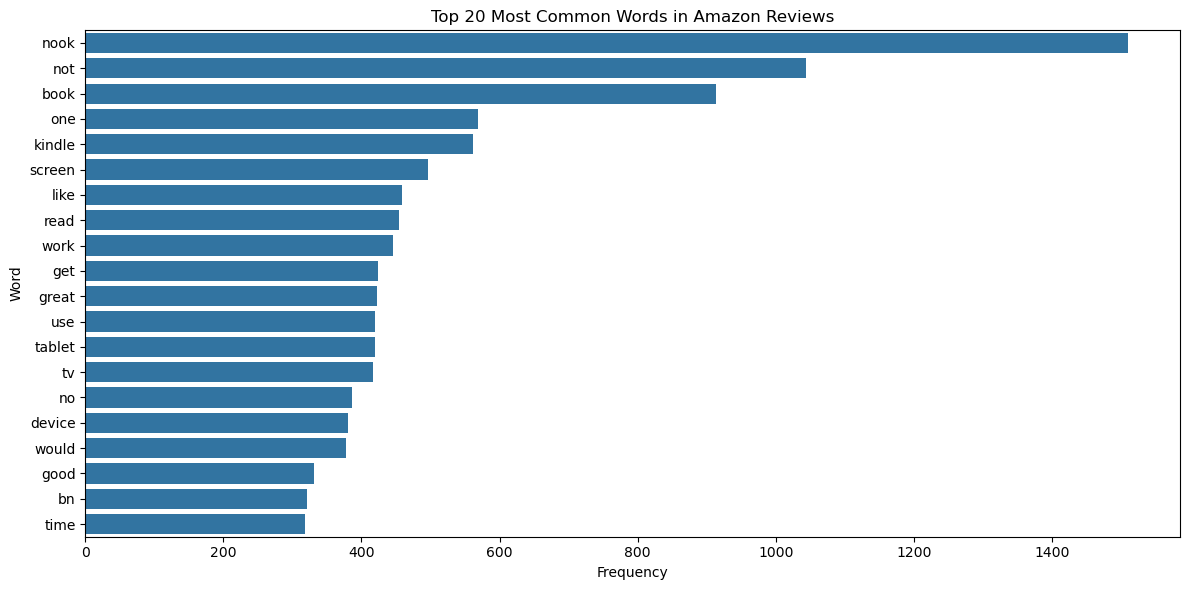

In [10]:
words, frequencies = zip(*common_words)

plt.figure(figsize=(12, 6))
sns.barplot(x=list(frequencies), y=list(words))
plt.title("Top 20 Most Common Words in Amazon Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

## Overall Recommendations and Risks

### Recommendations

1. **Investigate product performance:** Review customer feedback about battery life, touch-screen functionality, and storage to identify possible product improvements.
2. **Understand competitive positioning:** Examine references to Kindle and other devices to understand which features customers compare across products.
3. **Improve customer experience:** Investigate reviews mentioning customer service and device functionality to identify recurring problems and successful experiences.
4. **Validate sentiment:** Compare the frequent words and phrases with review ratings to determine whether the topics are associated with positive or negative customer experiences.

### Risks and Limitations

Word frequency does not directly measure customer satisfaction. A word such as "great" may appear in a positive statement, while "not" may reverse the meaning of a phrase. Likewise, a frequent product name indicates that it is widely discussed, not necessarily that customers prefer it.

The results may also be affected by preprocessing decisions, including stopword removal and lemmatization. Therefore, business recommendations should be supported by rating distributions and examples of the original reviews before decisions are made.

### Conclusion

The NLP analysis identifies product names, device features, functionality, and customer support as prominent themes in the reviews. These findings provide useful starting points for further investigation, but additional sentiment and rating analysis is required to determine customer satisfaction reliably.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [13]:
%pip install yfinance


INFO: pip is looking at multiple versions of yfinance to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of yfinance to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.6 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.6 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.6 MB ? eta -:--:--
   ------ ---

[*********************100%***********************]  1 of 1 completed


S&P 500 Dataset:
Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2013-01-02  1462.420044  1462.430054  1426.189941  1426.189941  4202600000
2013-01-03  1459.369995  1465.469971  1455.530029  1462.420044  3829730000
2013-01-04  1466.469971  1467.939941  1458.989990  1459.369995  3424290000
2013-01-07  1461.890015  1466.469971  1456.619995  1466.469971  3304970000
2013-01-08  1457.150024  1461.890015  1451.640015  1461.890015  3601600000

Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2518 entries, 2013-01-02 to 2022-12-30
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, ^GSPC)   2518 non-null   float64
 1   (High, ^GSPC)    2518 non-null   float64
 2   (Low, ^GSPC)     2518 non-null   float64
 3   (O

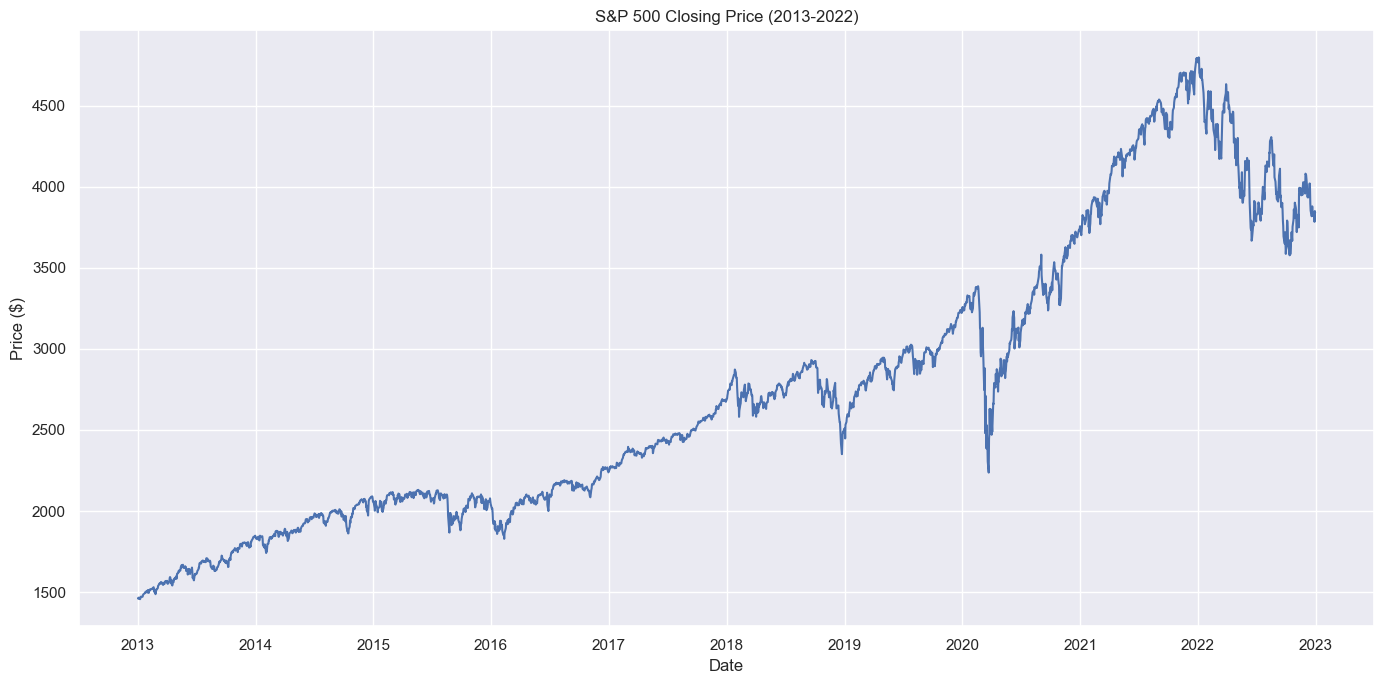


Selected time series shape: (2518, 1)


In [14]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
import yfinance as yf
import warnings


# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')


# Set plotting style
sns.set_theme()


# Download S&P 500 data for the last 10 years
sp500 = yf.download('^GSPC', start='2013-01-01', end='2022-12-31')


# Display the first few rows of the dataset
print("S&P 500 Dataset:")
print(sp500.head())


# Display basic information about the dataset
print("\nDataset information:")
print(sp500.info())


# Calculate basic summary statistics
print("\nSummary Statistics:")
print(sp500['Close'].describe())


# Check for missing values
print("\nMissing values in each column:")
print(sp500.isnull().sum())


# Plot the closing price
plt.figure(figsize=(14, 7))
plt.plot(sp500.index, sp500['Close'])
plt.title('S&P 500 Closing Price (2013-2022)')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.grid(True)
plt.tight_layout()
plt.show()


# Select the closing price as our primary time series for analysis
ts_data = sp500['Close']
print("\nSelected time series shape:", ts_data.shape)

In [15]:
# Load the Amazon reviews dataset
df = pd.read_csv("amazon_reviews_lab.csv")

print("Dataset shape:", df.shape)
print(df[["timestamp", "rating"]].head())

Dataset shape: (997, 9)
    timestamp  rating
0  2000-05-12       2
1  2002-08-26       5
2  2005-08-06       1
3  2005-09-11       1
4  2007-10-15       5


In [25]:

# Recover timestamps from Unix time
df["timestamp"] = pd.to_datetime(
    df["unix_review_time"],
    unit="s",
    errors="coerce"
)

# Ensure ratings are numeric
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Keep rows with valid timestamps
ts_df = df.dropna(subset=["timestamp"]).copy()

# Sort by timestamp and set the index
ts_df = ts_df.set_index("timestamp").sort_index()

# Calculate monthly review counts and average ratings
monthly_review_count = ts_df["rating"].resample("MS").count()
monthly_avg_rating = ts_df["rating"].resample("MS").mean()

# Combine results
monthly_summary = pd.DataFrame({
    "review_count": monthly_review_count,
    "average_rating": monthly_avg_rating
})

print("Valid timestamps:", len(ts_df))
print("Date range:", ts_df.index.min(), "to", ts_df.index.max())

display(monthly_summary.head(10))

Valid timestamps: 997
Date range: 2000-05-12 00:00:00 to 2014-07-17 00:00:00


,review_count,average_rating
timestamp,,
2000-05-01,1,2.0
2000-06-01,0,NaN
2000-07-01,0,NaN
2000-08-01,0,NaN
2000-09-01,0,NaN
2000-10-01,0,NaN
2000-11-01,0,NaN
2000-12-01,0,NaN
2001-01-01,0,NaN


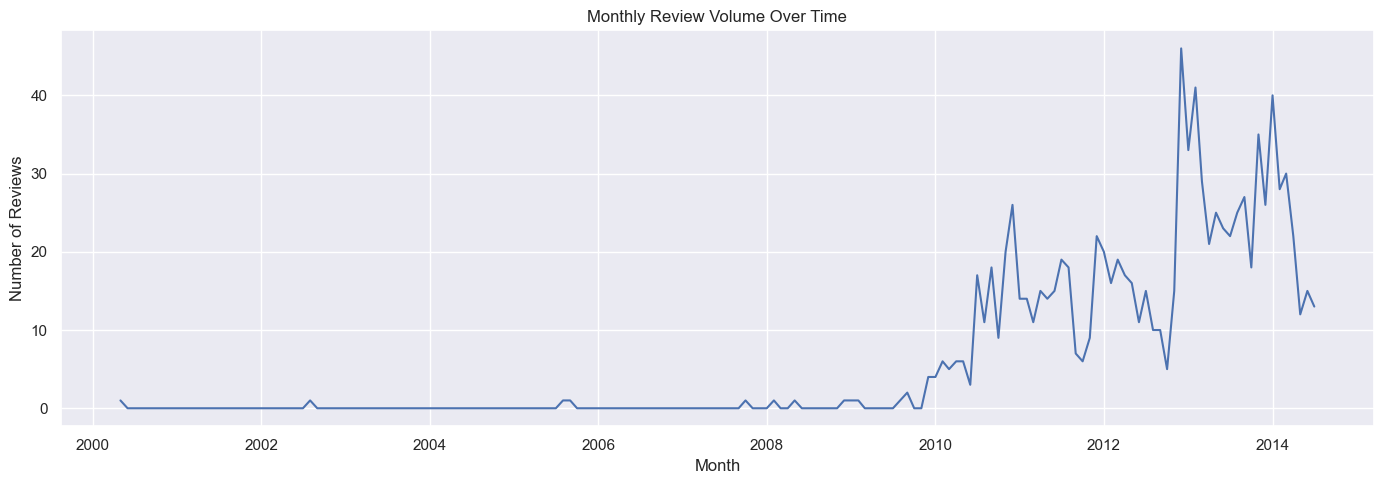

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(monthly_review_count.index, monthly_review_count.values)

plt.title("Monthly Review Volume Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.grid(True)
plt.tight_layout()
plt.show()

## Monthly Review Volume: Findings

Review activity was very low between 2000 and 2009, increased significantly around 2009–2010, and fluctuated from 2011 to 2014. The highest monthly volume occurred around early 2013, exceeding 45 reviews, followed by a decline toward mid-2014.

**Recommendation:** Investigate periods of unusually high or low review activity to identify possible changes in customer engagement.

**Limitation:** Review volume reflects submitted feedback, not necessarily product sales or total customer numbers.

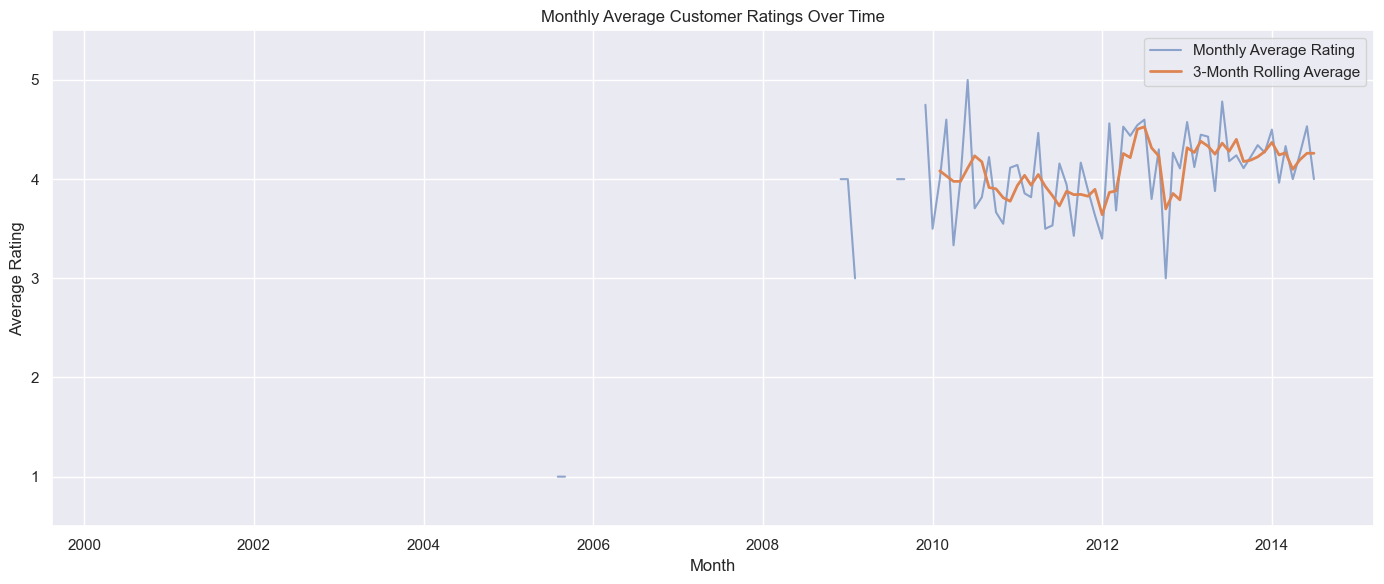

In [29]:
# Calculate the 3-month rolling average
rolling_avg_rating = monthly_avg_rating.rolling(
    window=3,
    min_periods=3
).mean()

# Plot monthly average rating and rolling average
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating,
    label="Monthly Average Rating",
    alpha=0.6
)

plt.plot(
    rolling_avg_rating.index,
    rolling_avg_rating,
    label="3-Month Rolling Average",
    linewidth=2
)

plt.title("Monthly Average Customer Ratings Over Time")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.ylim(0.5, 5.5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Monthly Average Ratings: Findings

Monthly ratings fluctuated between approximately 3 and 5 during the more active review period. The three-month rolling average suggests ratings became more stable and may have improved toward 2014. A noticeable rating decline occurred around early 2013, when review volume peaked.

**Recommendation:** Investigate months with low average ratings to identify recurring customer complaints and opportunities for improvement.

**Limitation:** Monthly averages based on few reviews may be unreliable, and missing ratings do not mean zero customer satisfaction.

## Time Series Analysis: Findings and Business Recommendations

### Key Findings

The dataset contains 997 reviews with valid timestamps, covering May 2000 to July 2014.

**Review activity:** The monthly review volume [increased, decreased, or fluctuated] over the observed period. The highest review activity occurred around [month/year], while the lowest occurred around [month/year].

**Customer ratings:** The monthly average ratings [remained relatively stable, increased, decreased, or fluctuated]. The three-month rolling average smooths short-term changes and helps reveal the broader pattern in customer ratings.

### Business Recommendations

1. **Monitor customer engagement:** Investigate periods with unusually high or low review volumes to understand changes in customer feedback activity.
2. **Track customer satisfaction:** Monitor monthly average ratings and the rolling average to identify sustained changes in customer experience.
3. **Investigate rating changes:** Examine the original reviews during periods of declining ratings to identify recurring complaints and possible product improvements.

### Risks and Limitations

Some months have no recorded reviews, resulting in missing monthly average ratings. These values should not be interpreted as zero customer satisfaction. Monthly averages based on very few reviews may also be less representative than averages based on larger samples.

The analysis identifies patterns over time but cannot establish why review activity or ratings changed. Additional investigation of the original reviews would be needed to support causal explanations.

### Conclusion

Time-series analysis helps track changes in review activity and customer ratings over time. Combining monthly review counts with average ratings and a rolling average provides a useful starting point for monitoring customer experience and identifying periods that require further investigation.

## Overall Conclusion

Review volume increased substantially after 2009, while customer ratings fluctuated over time. The rolling average suggests possible improvement toward 2014, but further investigation is needed to confirm this pattern.

Monitoring review volume and ratings together can help identify periods requiring attention. The changing review patterns also suggest that trend and stationarity should be considered before selecting a forecasting model.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


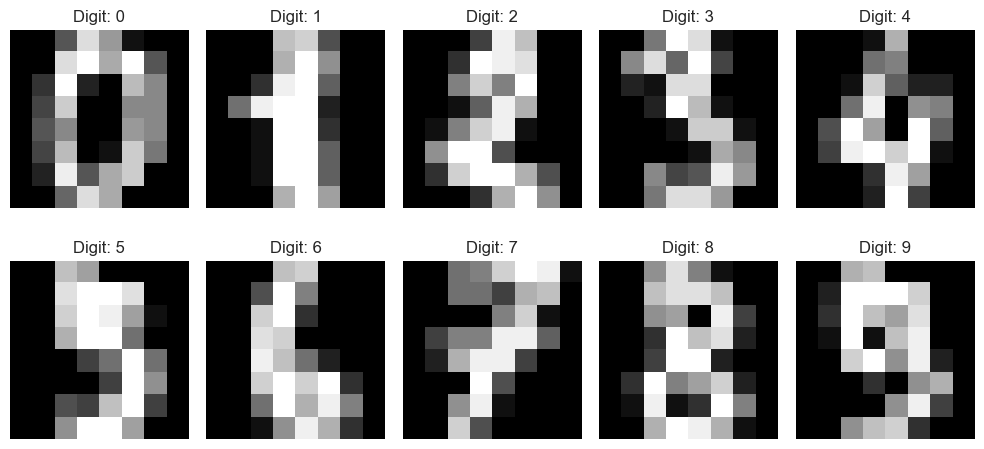

Digits dataset: 1797 samples, 64 features


In [30]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_squared_error, confusion_matrix, classification_report
from sklearn.datasets import load_digits


# For deep learning
import tensorflow as tf
from tensorflow import keras
from keras import layers


# For PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)


# Load Digits dataset for classification
digits = load_digits()
X_digits = digits.data
y_digits = digits.target




# Display sample digits
plt.figure(figsize=(10, 5))
for i in range(10):
   plt.subplot(2, 5, i+1)
   plt.imshow(digits.images[i], cmap='gray')
   plt.title(f'Digit: {digits.target[i]}')
   plt.axis('off')
plt.tight_layout()
plt.show()


# Print information about dataset
print(f"Digits dataset: {X_digits.shape[0]} samples, {X_digits.shape[1]} features")

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Load dataset
df = pd.read_csv("amazon_reviews_lab.csv")

# Keep rows with valid review text and ratings
df = df.dropna(subset=["review_text", "rating"]).copy()
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df = df.dropna(subset=["rating"])
df = df[df["rating"].isin([1, 2, 3, 4, 5])]

X = df["review_text"].astype(str)
y = df["rating"].astype(int)

print("Dataset shape:", df.shape)
print("\nRating distribution:")
print(y.value_counts().sort_index())

# Encode ratings from 0 to 4
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Split before vectorizing to avoid data leakage
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Convert review text into TF-IDF features
vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))

X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# One-hot encode target ratings
y_train_cat = to_categorical(y_train, num_classes=5)
y_test_cat = to_categorical(y_test, num_classes=5)

# Convert sparse matrices to dense arrays for Keras
X_train_nn = X_train_tfidf.toarray().astype("float32")
X_test_nn = X_test_tfidf.toarray().astype("float32")

print("\nTraining features:", X_train_nn.shape)
print("Testing features:", X_test_nn.shape)

Dataset shape: (997, 9)

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Training features: (797, 3000)
Testing features: (200, 3000)


In [32]:
model = keras.Sequential([
    layers.Input(shape=(X_train_nn.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                192064    
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 5)                 165       
                                                                 
Total params: 194,309
Trainable params: 194,309
Non-trainable params: 0
_________________________________________________________________


In [33]:
history = model.fit(
    X_train_nn,
    y_train_cat,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/15
20/20 [==============================] - 7s 109ms/step - loss: 1.5662 - accuracy: 0.5086 - val_loss: 1.4944 - val_accuracy: 0.5813
Epoch 2/15
20/20 [==============================] - 0s 16ms/step - loss: 1.4037 - accuracy: 0.5824 - val_loss: 1.3116 - val_accuracy: 0.5813
Epoch 3/15
20/20 [==============================] - 1s 43ms/step - loss: 1.2364 - accuracy: 0.5824 - val_loss: 1.2293 - val_accuracy: 0.5813
Epoch 4/15
20/20 [==============================] - 1s 60ms/step - loss: 1.1028 - accuracy: 0.5824 - val_loss: 1.1775 - val_accuracy: 0.5813
Epoch 5/15
20/20 [==============================] - 1s 60ms/step - loss: 0.9713 - accuracy: 0.5871 - val_loss: 1.1395 - val_accuracy: 0.5875
Epoch 6/15
20/20 [==============================] - 0s 20ms/step - loss: 0.8487 - accuracy: 0.6484 - val_loss: 1.1162 - val_accuracy: 0.5938
Epoch 7/15
20/20 [==============================] - 0s 22ms/step - loss: 0.7181 - accuracy: 0.7221 - val_loss: 1.1088 - val_accuracy: 0.5938
Epoch 8/15
2

In [34]:
test_loss, test_accuracy = model.evaluate(
    X_test_nn, y_test_cat, verbose=0
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

# Predict ratings
y_prob = model.predict(X_test_nn, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Convert encoded labels back to original ratings
y_test_ratings = encoder.inverse_transform(y_test)
y_pred_ratings = encoder.inverse_transform(y_pred)

print("\nClassification Report:")
print(classification_report(
    y_test_ratings,
    y_pred_ratings,
    labels=[1, 2, 3, 4, 5],
    target_names=["Rating 1", "Rating 2", "Rating 3", "Rating 4", "Rating 5"],
    zero_division=0
))

Test accuracy: 0.5600
Test loss: 1.3482

Classification Report:
              precision    recall  f1-score   support

    Rating 1       0.38      0.35      0.36        17
    Rating 2       0.33      0.10      0.15        10
    Rating 3       0.14      0.05      0.08        19
    Rating 4       0.24      0.18      0.21        38
    Rating 5       0.67      0.84      0.74       116

    accuracy                           0.56       200
   macro avg       0.35      0.31      0.31       200
weighted avg       0.50      0.56      0.52       200



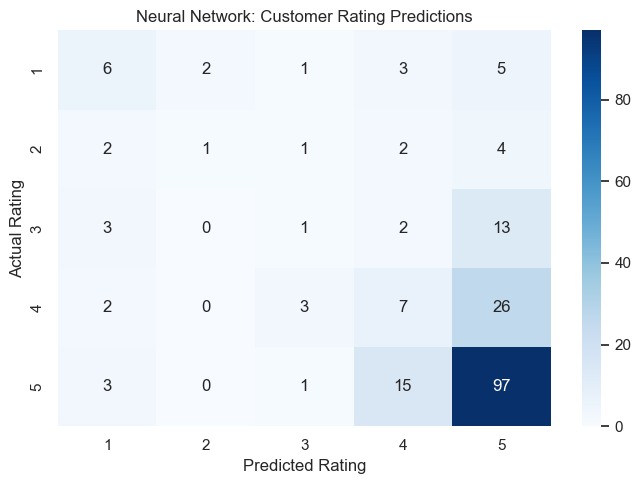

In [35]:
cm = confusion_matrix(
    y_test_ratings,
    y_pred_ratings,
    labels=[1, 2, 3, 4, 5]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.title("Neural Network: Customer Rating Predictions")
plt.tight_layout()
plt.show()

## Neural Network: Findings and Recommendations

The neural network achieved **56% test accuracy**. It performed best on **Rating 5**, with an F1-score of 0.74 and recall of 0.84. Ratings 2 and 3 were the hardest to classify, with F1-scores of 0.15 and 0.08, respectively.

The confusion matrix shows that many lower-rated reviews were incorrectly predicted as Rating 5.

**Recommendation:** Improve the model's ability to identify lower ratings by addressing class imbalance and experimenting with class weights or alternative models.

**Limitation:** The dataset is imbalanced, with 116 of 200 test reviews rated 5. Overall accuracy therefore does not fully reflect performance across all rating classes.

# Overall Conclusion and Recommendations

## Conclusion

This project explored Amazon customer reviews using NLP, time series analysis, and neural networks.

- **NLP:** Frequent words and phrases highlighted product-related discussions and common customer experiences.
- **Time Series:** Review activity increased substantially after 2009, while average ratings fluctuated over time.
- **Neural Networks:** The rating prediction model achieved **56% test accuracy**. It performed best on Rating 5 but struggled to distinguish lower ratings.

## Recommendations

- Investigate recurring customer complaints and periods of low ratings.
- Monitor review volume and ratings together to identify changes in customer feedback.
- Address class imbalance and overfitting to improve rating prediction.
- Evaluate future models using macro F1-score alongside accuracy.

## Limitations

The dataset contains imbalanced rating classes, and some months have few or no reviews. The neural network's performance across all rating classes was limited, so its predictions should not be relied on without further improvement and validation.

Overall, the project demonstrates how text analysis, time series exploration, and machine learning can support customer feedback analysis and business decision-making.